<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_ap_carro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio V, apêndice: odometria de um carro

## O modelo de bicicleta, o arco exato da Exp, e a calibração das rodas por dois circuitos fechados

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Anterior:** [X5_dualcomplexos.ipynb](X5_dualcomplexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_dualcomplexos.ipynb))

**O modelo de bicicleta.** Para a cinemática em baixa velocidade (sem derrapagem), um carro se comporta como uma bicicleta: junta-se as duas rodas de cada eixo numa só, no meio do eixo. Com o ponto de referência no meio do eixo traseiro, a velocidade de avanço $v$, o ângulo de esterçamento $\delta$ das rodas dianteiras e a distância entre eixos $L$, a velocidade no corpo é

$$\omega=\frac{v\tan\delta}{L},\qquad \mathbf v_{\text{corpo}}=v\ (\text{para a frente, sem componente lateral}).$$

Com $v$ e $\delta$ constantes durante um intervalo $\Delta t$, o carro percorre **exatamente** um arco de círculo, e a pose avança por $q\leftarrow q\,\mathrm{Exp}(\omega\Delta t,\ v\Delta t)$, sem erro de integração nenhum (notebook V(a), seção 5). O passo de Euler, $x\mathrel{+}=v\cos\theta\,\Delta t$, $y\mathrel{+}=v\,\mathrm{sen}\,\theta\,\Delta t$, $\theta\mathrel{+}=\omega\Delta t$, troca o arco por um segmento de reta.

**Odometria pelas rodas.** Na prática, $v$ e $\omega$ vêm de **encoders** nas rodas traseiras: contando os pulsos de cada roda, sabe-se quanto ela girou, e, com o raio $r$, quanto andou. Com as distâncias $s_e$ e $s_d$ das rodas esquerda e direita e a bitola $B$ (a distância entre elas): $v\Delta t=(s_e+s_d)/2$ e $\omega\Delta t=(s_d-s_e)/B$. Se os raios ou a bitola estiverem errados, mesmo que por meio por cento, o erro vira um **desvio sistemático** que se acumula sem parar.

**O que este notebook mostra.**
1. O arco da $\mathrm{Exp}$ é a trajetória exata do modelo, e o seu ponto fixo é o centro de curva de **Ackermann**, sobre a reta do eixo traseiro.
2. Euler tem erro de ordem 1, o ponto médio de ordem 2, a $\mathrm{Exp}$ é exata.
3. A calibração: com dois circuitos fechados, um em cada sentido (a ideia do *UMBmark* de Borenstein e Feng), um Gauss–Newton no grupo estima a diferença entre os raios e a bitola, **mas não a escala**: um circuito fechado não sabe o próprio tamanho. Com uma reta de comprimento conhecido, os três parâmetros saem certos.

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

rng = np.random.default_rng(55)

def wrap(a):
    return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

class DC:
    """Número dual-complexo q = a + b·ε, com a = a0 + i·a1 e b = b0 + i·b1, e a regra z·ε = ε·z̄.
    Guardado como quatro reais (a0, a1, b0, b1), que podem ser floats, Fractions ou números duais."""
    def __init__(self, a0, a1, b0, b1):
        self.a0, self.a1, self.b0, self.b1 = a0, a1, b0, b1
    def __mul__(self, o):
        if not isinstance(o, DC):                       # número real vezes dual-complexo
            return DC(self.a0 * o, self.a1 * o, self.b0 * o, self.b1 * o)
        # a = a1·a2 ;  b = a1·b2 + b1·conj(a2)   (a regra z ε = ε z̄ conjuga o fator que "passa" por ε)
        a0 = self.a0 * o.a0 - self.a1 * o.a1
        a1 = self.a0 * o.a1 + self.a1 * o.a0
        b0 = (self.a0 * o.b0 - self.a1 * o.b1) + (self.b0 * o.a0 + self.b1 * o.a1)
        b1 = (self.a0 * o.b1 + self.a1 * o.b0) + (self.b1 * o.a0 - self.b0 * o.a1)
        return DC(a0, a1, b0, b1)
    __rmul__ = __mul__
    def __add__(self, o): return DC(self.a0 + o.a0, self.a1 + o.a1, self.b0 + o.b0, self.b1 + o.b1)
    def __sub__(self, o): return DC(self.a0 - o.a0, self.a1 - o.a1, self.b0 - o.b0, self.b1 - o.b1)
    def conj(self):
        """q* = ā − b ε: o inverso de um dual-complexo unitário."""
        return DC(self.a0, -self.a1, -self.b0, -self.b1)
    def norma2(self):
        """q q* = |a|² (um número real: a parte dual se cancela)."""
        return self.a0 * self.a0 + self.a1 * self.a1
    @property
    def a(self): return complex(self.a0, self.a1)
    @property
    def b(self): return complex(self.b0, self.b1)
    def __repr__(self): return f"({self.a:.6g}) + ({self.b:.6g})ε"

def pose(theta, t):
    """A pose 'girar θ, transladar t' (t complexo): q = r + (t r̄ / 2) ε, com r = e^{iθ/2}."""
    r = np.exp(0.5j * theta); b = t * np.conj(r) / 2
    return DC(r.real, r.imag, b.real, b.imag)

def angulo(q):
    return float(wrap(2 * np.arctan2(q.a1, q.a0)))

def translacao(q):
    """t = 2 b a / |a|² (vale também para q não unitário)."""
    return 2 * q.b * q.a / q.norma2()

def aplica(q, p):
    """O ponto p (complexo) levado pela pose q: a translação de q · (translação até p)."""
    return translacao(q * pose(0.0, p))

def Exp(w, v):
    """Velocidade (ω, v) no corpo, v complexo, por uma unidade de tempo: um arco de círculo (ou um segmento, se ω = 0)."""
    return pose(w, v * np.exp(0.5j * w) * sinc(w / 2))

def Log(q):
    th = angulo(q)
    return th, translacao(q) / (np.exp(0.5j * th) * sinc(th / 2))

L, BITOLA = 2.7, 1.6                       # distância entre eixos e bitola (m)

def velocidade_corpo(v, delta):
    return v * np.tan(delta) / L, v        # (ω, v)

## 1. Ackermann: o centro de curva é o ponto fixo da Exp

Com esterçamento constante, o carro gira em torno de um ponto fixo do mundo, a uma distância $R=L/\tan\delta$ do meio do eixo traseiro, **sobre a reta do eixo traseiro** (para a esquerda, se $\delta>0$). É o princípio de Ackermann: todas as rodas giram em torno desse mesmo ponto, e nenhuma escorrega de lado. Duas conferências: o ponto fixo do passo $\mathrm{Exp}(\omega\Delta t,v\Delta t)$, levado ao mundo, é esse centro; e a roda dianteira, no ponto $L$ do corpo, se move exatamente na direção para onde está esterçada.

In [2]:
v, delta, dt = 5.0, np.radians(12), 0.1
w, vv = velocidade_corpo(v, delta)
R = L / np.tan(delta)
q = pose(np.radians(30), 3 + 2j)                      # uma pose qualquer
passo = Exp(w * dt, vv * dt)
centro = aplica(q, 1j * R)                           # R para a esquerda, sobre a reta do eixo traseiro
# ponto fixo do deslocamento no mundo, q·passo·q⁻¹
dq = q * passo * q.conj()
fixo = translacao(dq) / (1 - np.exp(1j * angulo(dq)))
print(f"raio de curva R = L/tan δ = {R:.4f} m;  centro esperado {centro:.5f};  ponto fixo do passo {fixo:.5f}")
confere("o ponto fixo da Exp é o centro de Ackermann", fixo, centro, tol=1e-12)

# a roda dianteira: velocidade do ponto L do corpo = v + ω·i·L (no corpo); a direção dela tem de ser δ
vel_dianteira = vv + w * 1j * L
confere("a roda dianteira anda para onde está esterçada (sem derrapar)", np.angle(vel_dianteira), delta, tol=1e-14)

# 200 passos: todos os pontos à distância R do centro
cam = [q]
for _ in range(200):
    cam.append(cam[-1] * passo)
confere("200 passos depois, o carro continua no círculo de raio R", max(abs(abs(translacao(p) - centro) - R) for p in cam), 0, tol=1e-11)

raio de curva R = L/tan δ = 12.7025 m;  centro esperado -3.35125+13.00069j;  ponto fixo do passo -3.35125+13.00069j
OK   o ponto fixo da Exp é o centro de Ackermann:  diferença máxima = 3.42e-14
OK   a roda dianteira anda para onde está esterçada (sem derrapar):  diferença máxima = 0.00e+00
OK   200 passos depois, o carro continua no círculo de raio R:  diferença máxima = 4.26e-14


## 2. Euler, ponto médio e Exp

Meia volta na rotatória ($v=5$ m/s, $\delta=12°$): o carro deveria chegar ao ponto diametralmente oposto, $2Ri$. A tabela mostra o erro de posição na chegada para vários $\Delta t$. (Por que meia volta e não uma volta inteira? Com $\omega$ constante, o Euler percorre um polígono regular, que **fecha** depois de uma volta: o erro na chegada seria zero, por simetria, e esconderia o erro do caminho.)

In [3]:
def integra(metodo, dt, v=5.0, delta=np.radians(12)):
    w, vv = velocidade_corpo(v, delta)
    T = np.pi / w; n = int(round(T / dt)); dt = T / n              # meia volta
    x, y, th = 0.0, 0.0, 0.0
    q = pose(0.0, 0j)
    for _ in range(n):
        if metodo == "Euler":
            x += vv * np.cos(th) * dt; y += vv * np.sin(th) * dt; th += w * dt
        elif metodo == "ponto médio":
            tm = th + w * dt / 2; x += vv * np.cos(tm) * dt; y += vv * np.sin(tm) * dt; th += w * dt
        else:
            q = q * Exp(w * dt, vv * dt)
    alvo = 2j * L / np.tan(delta)
    return abs(complex(x, y) - alvo) if metodo != "Exp" else abs(translacao(q) - alvo)

passos = [0.4, 0.2, 0.1, 0.05]
print("   Δt      Euler        ponto médio     Exp")
tab = {m: [integra(m, h) for h in passos] for m in ["Euler", "ponto médio", "Exp"]}
for i, h in enumerate(passos):
    print(f"{h:6.2f}   {tab['Euler'][i]:9.2e}     {tab['ponto médio'][i]:9.2e}     {tab['Exp'][i]:9.2e}")
ordem = lambda e: np.polyfit(np.log(passos), np.log(e), 1)[0]
print(f"ordem observada: Euler {ordem(tab['Euler']):.2f}, ponto médio {ordem(tab['ponto médio']):.2f}")
confere("Euler tem ordem 1", ordem(tab["Euler"]), 1, tol=0.05)
confere("ponto médio tem ordem 2", ordem(tab["ponto médio"]), 2, tol=0.05)
confere("a Exp é exata (erro de arredondamento)", max(tab["Exp"]), 0, tol=1e-10)

   Δt      Euler        ponto médio     Exp
  0.40    2.00e+00      2.61e-02      9.82e-15
  0.20    9.98e-01      6.53e-03      9.40e-15
  0.10    4.99e-01      1.63e-03      8.00e-15
  0.05    2.49e-01      4.08e-04      3.49e-14
ordem observada: Euler 1.00, ponto médio 2.00
OK   Euler tem ordem 1:  diferença máxima = 1.55e-04
OK   ponto médio tem ordem 2:  diferença máxima = 3.26e-04
OK   a Exp é exata (erro de arredondamento):  diferença máxima = 3.49e-14


## 3. Calibrar as rodas com dois circuitos

O carro tem raios de roda nominais de 30 cm e bitola nominal de 1,6 m. Na verdade, a roda esquerda tem 30,15 cm (pneu mais cheio), a direita 29,94 cm, e a bitola efetiva é 1,62 m (o ponto de contato do pneu não é onde a ficha técnica diz). O carro percorre um circuito retangular de 20 m × 10 m, voltando ao ponto de partida, uma vez no sentido anti-horário e uma vez no horário. Os encoders têm 2048 pulsos por volta (a medida é arredondada para o pulso inteiro).

Um erro nos raios **iguais** muda a escala de tudo; uma **diferença** entre os raios faz o carro curvar quando acha que vai reto; um erro na bitola muda o quanto ele acha que girou nas curvas. Num circuito só, a diferença de raios e a bitola se confundem; nos dois sentidos, os efeitos da bitola se invertem e os da diferença de raios não, e eles se separam (é o argumento do UMBmark).

O resíduo de cada circuito é $\mathrm{Log}(q_{\text{odo}}^{-1}\,q_{\text{verdade}})$ na chegada, onde $q_{\text{verdade}}$ é a pose de chegada verdadeira (praticamente a de partida: o carro volta ao mesmo lugar, conferido por um marco no chão). Os parâmetros são três: os dois raios e a bitola. Vale a pena prever, antes de rodar: dois circuitos dão seis números; três parâmetros; deve dar certo?

In [4]:
PULSOS = 2048
r_ver = np.array([0.3015, 0.2994]); B_ver = 1.62           # verdade: raios esquerdo, direito; bitola
r_nom = np.array([0.30, 0.30]);     B_nom = 1.60           # o que o carro acha

def circuito(sentido, dt=0.05, v=3.0):
    """Os controles (v, δ) de um retângulo 20 × 10 com curvas de raio 4 m, no sentido +1 (anti-horário) ou −1."""
    R = 4.0; delta = sentido * np.arctan(L / R)
    w = v / R
    trechos = []                                   # (v, δ, Δt): o Δt de cada trecho é ajustado para o trecho caber num número inteiro de passos
    for reto in [20 - 2 * R, 10 - 2 * R] * 2:
        n = int(round(reto / v / dt)); trechos += [(v, 0.0, reto / v / n)] * n
        n = int(round((np.pi / 2) / w / dt)); trechos += [(v, delta, (np.pi / 2) / w / n)] * n
    return trechos

def pulsos_das_rodas(trechos):
    """O carro anda de verdade; cada roda traseira gira s/r_ver; o encoder conta pulsos inteiros (acumulados)."""
    q = pose(0.0, 0j); ang = np.zeros(2); contagens = [np.zeros(2, dtype=int)]
    for v, delta, dt in trechos:
        w, vv = velocidade_corpo(v, delta)
        q = q * Exp(w * dt, vv * dt)
        s = np.array([vv * dt - w * dt * B_ver / 2, vv * dt + w * dt * B_ver / 2])   # distâncias das rodas e, d
        ang += s / r_ver
        contagens.append(np.floor(ang / (2 * np.pi) * PULSOS).astype(int))
    return q, np.array(contagens)

def odometria(contagens, r, B):
    q = pose(0.0, 0j)
    for d in np.diff(contagens, axis=0):
        s = d / PULSOS * 2 * np.pi * r
        q = q * Exp((s[1] - s[0]) / B, (s[0] + s[1]) / 2 + 0j)
    return q

dados = {}
for sentido in [+1, -1]:
    q_fim, cont = pulsos_das_rodas(circuito(sentido))
    dados[sentido] = cont
    print(f"sentido {'anti-horário' if sentido > 0 else 'horário     '}: a verdade termina a {abs(translacao(q_fim)):.1e} m da partida (o circuito fecha)")
    q_odo = odometria(cont, r_nom, B_nom)
    print(f"   a odometria com os parâmetros nominais acha que terminou a {abs(translacao(q_odo) - translacao(q_fim)):.2f} m da verdade, "
          f"com {np.degrees(wrap(angulo(q_odo) - angulo(q_fim))):+.1f}° de erro de rumo")
    dados[sentido] = (cont, q_fim)

sentido anti-horário: a verdade termina a 3.2e-14 m da partida (o circuito fecha)
   a odometria com os parâmetros nominais acha que terminou a 2.23 m da verdade, com +17.2° de erro de rumo
sentido horário     : a verdade termina a 3.2e-14 m da partida (o circuito fecha)
   a odometria com os parâmetros nominais acha que terminou a 1.30 m da verdade, com +9.3° de erro de rumo


In [5]:
def Log3(q):
    w, v = Log(q); return np.array([w, v.real, v.imag])

def residuo(p, experimentos):
    r = p[:2]; B = p[2]
    return np.concatenate([Log3(odometria(cont, r, B).conj() * q_fim) for cont, q_fim in experimentos])

def calibra(experimentos, n_iter=6):
    p = np.array([*r_nom, B_nom])
    print(" it    raio esq. (cm)   raio dir. (cm)   bitola (m)    |resíduo|")
    for it in range(n_iter):
        r0 = residuo(p, experimentos)
        print(f"{it:3d}    {p[0] * 100:9.4f}        {p[1] * 100:9.4f}       {p[2]:8.5f}     {np.linalg.norm(r0):.2e}")
        J = np.zeros((len(r0), 3)); h = 1e-7
        for k in range(3):
            d = np.zeros(3); d[k] = h
            J[:, k] = (residuo(p + d, experimentos) - residuo(p - d, experimentos)) / (2 * h)
        p = p - np.linalg.lstsq(J, r0, rcond=None)[0]
    print(f"verdade:   {r_ver[0] * 100:9.4f}        {r_ver[1] * 100:9.4f}       {B_ver:8.5f}")
    print(f"número de condição do jacobiano: {np.linalg.cond(J):.3g}")
    return p

p2 = calibra([dados[+1], dados[-1]])
razoes = np.array([p2[0] / r_ver[0], p2[1] / r_ver[1], p2[2] / B_ver])
print(f"\nestimado / verdadeiro, para os três parâmetros: {razoes}")
confere("com dois circuitos fechados, os três parâmetros saem errados pelo MESMO fator", razoes.max() - razoes.min(), 0, tol=5e-4)
p_ver = np.array([*r_ver, B_ver])
for k in [0.5, 1.0, 2.0]:
    print(f"resíduo com os parâmetros verdadeiros multiplicados por {k}:  {np.linalg.norm(residuo(k * p_ver, [dados[+1], dados[-1]])):.2e}")

 it    raio esq. (cm)   raio dir. (cm)   bitola (m)    |resíduo|
  0      30.0000          30.0000        1.60000     2.61e+00
  1      27.7130          27.5180        1.49080     8.18e-02
  2      28.2638          28.0669        1.51864     4.04e-04
  3       0.2449           0.2432        0.01316     3.32e-04
  4       0.1298           0.1289        0.00697     2.92e-04
  5       0.0164           0.0163        0.00088     2.02e-03
verdade:     30.1500          29.9400        1.62000
número de condição do jacobiano: 3.58e+07

estimado / verdadeiro, para os três parâmetros: [0.000478 0.000478 0.000478]
OK   com dois circuitos fechados, os três parâmetros saem errados pelo MESMO fator:  diferença máxima = 4.76e-09
resíduo com os parâmetros verdadeiros multiplicados por 0.5:  5.63e-04
resíduo com os parâmetros verdadeiros multiplicados por 1.0:  9.10e-04
resíduo com os parâmetros verdadeiros multiplicados por 2.0:  1.70e-03


**O que deu errado.** O Gauss–Newton fechou os circuitos em duas iterações (o resíduo caiu ao nível da quantização dos encoders), mas depois **saiu passeando**: os três parâmetros encolhem juntos, iteração após iteração, sempre na mesma proporção entre si, e chegam a raios de décimos de milímetro, sem que o resíduo reaja. O número de condição do jacobiano é da ordem de $10^7$. E os parâmetros verdadeiros multiplicados por $0{,}5$ ou por $2$ dão resíduos tão pequenos quanto os verdadeiros. O motivo é geométrico: se os dois raios e a bitola forem multiplicados pelo mesmo fator $k$, a odometria calcula um circuito $k$ vezes maior, com os mesmos ângulos, e um circuito que volta ao ponto de partida continua voltando ao ponto de partida. Um circuito fechado não tem **escala**: a escala é uma direção do espaço dos parâmetros em que o resíduo não muda (só a quantização dos encoders quebra a simetria, de leve, e é isso que deixa o número de condição finito; num problema sem quantização, o jacobiano seria exatamente singular). É o mesmo fenômeno da primeira pose livre no SLAM por grafo, e da escala do SLAM com uma câmera só.

A correção é uma medida com **escala**: o carro anda em linha reta até um marco a 20 m, conhecido com precisão.

In [6]:
# o terceiro experimento: 20 m em linha reta até um marco
reta = [(3.0, 0.0, 20 / 3.0 / 400)] * 400
q_fim, cont = pulsos_das_rodas(reta)
dados[0] = (cont, q_fim)
print(f"a verdade anda {abs(translacao(q_fim)):.3f} m; a odometria nominal acha que andou {abs(translacao(odometria(cont, r_nom, B_nom))):.3f} m\n")
p = calibra([dados[+1], dados[-1], dados[0]])
confere("agora os raios estimados batem com os verdadeiros (a menos de 0,1 mm)", p[:2], r_ver, tol=1e-4)
confere("e a bitola estimada bate com a verdadeira (a menos de 1 mm)", p[2], B_ver, tol=1e-3)

a verdade anda 20.000 m; a odometria nominal acha que andou 19.963 m

 it    raio esq. (cm)   raio dir. (cm)   bitola (m)    |resíduo|
  0      30.0000          30.0000        1.60000     2.76e+00
  1      30.1695          29.9581        1.62291     8.49e-02
  2      30.1509          29.9409        1.62004     5.04e-04
  3      30.1509          29.9409        1.62004     5.03e-04
  4      30.1509          29.9409        1.62004     5.03e-04
  5      30.1509          29.9409        1.62004     5.03e-04
verdade:     30.1500          29.9400        1.62000
número de condição do jacobiano: 157
OK   agora os raios estimados batem com os verdadeiros (a menos de 0,1 mm):  diferença máxima = 9.49e-06
OK   e a bitola estimada bate com a verdadeira (a menos de 1 mm):  diferença máxima = 3.57e-05


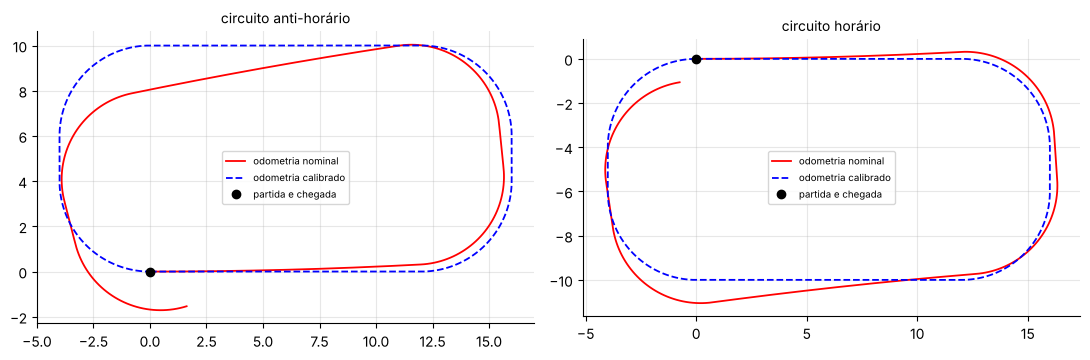

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, sentido in zip(axs, [+1, -1]):
    cont, q_fim = dados[sentido]
    for nome, r, B, est in [("nominal", r_nom, B_nom, "r-"), ("calibrado", p[:2], p[2], "b--")]:
        q = pose(0.0, 0j); pts = [0j]
        for d in np.diff(cont, axis=0):
            s = d / PULSOS * 2 * np.pi * r
            q = q * Exp((s[1] - s[0]) / B, (s[0] + s[1]) / 2 + 0j); pts.append(translacao(q))
        pts = np.array(pts); ax.plot(pts.real, pts.imag, est, lw=1.3, label=f"odometria {nome}")
    ax.plot(0, 0, "ko", ms=6, label="partida e chegada")
    ax.set_aspect("equal"); ax.legend(fontsize=7)
    ax.set_title(f"circuito {'anti-horário' if sentido > 0 else 'horário'}", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.** O passo da $\mathrm{Exp}$ tem por ponto fixo o centro de Ackermann, a roda dianteira anda na direção em que aponta, e, depois de 200 passos, o carro continua no círculo com erro de arredondamento: o arco é a solução exata do modelo de bicicleta. Euler e ponto médio mostram as ordens 1 e 2 esperadas.

Na calibração, diferenças de poucas décimas de milímetro nos raios e de 2 cm na bitola bastam para a odometria nominal terminar os circuitos com erros de 1,3 m e 2,2 m na posição e de 9° e 17° no rumo. Com os dois circuitos, o Gauss–Newton no grupo fecha os circuitos, mas deixa a escala solta: os três parâmetros derivam juntos, na proporção certa e no tamanho errado. Com a reta de 20 m, a escala aparece, o número de condição cai de cerca de $10^7$ para cerca de $10^2$, e os três parâmetros saem certos, até onde a quantização dos encoders permite. Na figura, a odometria calibrada (tracejada) fecha os dois circuitos.

## Exercícios

1. **Um circuito e a reta.** Calibre usando só o circuito anti-horário e a reta. O jacobiano fica $6\times3$; calcule o número de condição e compare com o dos três experimentos. Que combinação de parâmetros fica mal determinada agora?
2. **A banana do carro.** Acrescente ruído aos pulsos (por exemplo, roda que escorrega um pouco: some $\pm1$ pulso aleatório a cada passo) e repita a odometria mil vezes. Desenhe a nuvem das poses finais: é uma banana (notebook V(c), seção 4)?
3. **Derrapagem.** Em alta velocidade, o modelo de bicicleta cinemático falha: os pneus escorregam de lado, e aparece uma velocidade lateral $v_y\neq0$ no corpo. A $\mathrm{Exp}$ continua exata para $(\omega,v_x+iv_y)$ constantes? E o ponto fixo, onde fica agora?